<a href="https://colab.research.google.com/github/fergogu27-ctrl/EDPII/blob/main/Modelo_SIR_con_Metropolis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Proyecto: Ajuste de parámetros del modelo SIR

1. Graficar datos.
2. Programar la solución númerica del modelo SIR, con parametros libres.
3. PLantear un ajuste por minimos cuadrados, $X^2(a,b)$.
4. Usar el método MCMC(Metropolis Hastings) para optimizar $X^2$.
5. Remplantear con $pyMC$ en el enfoque bayesiano.

**PROBLEMA:**
Marinov, plantea este problema para un conjunto de datos a un brote de gripe en un internado. Estos datos se citaron por primera vez en  y se reproducen en la tabla siguiente; la solución obtenida por Murray. Según, los valores de los parámetros $a$ y $b$ son los siguientes: $a ≈ 0.00218$ y $b ≈ 0.4485$.

**Tabla de datos de Influenza en una escuela**

$
\boxed{
\begin{array}{lc}
\text{t} & 0 &  1& 2 & 3 & 4 & 5 & 6 & 7 & 8 & 9 & 10 & 11 &  12 & 13 & 14   \\
\hline
\text{$I(t)$} & 1& 3& 6& 25& 73& 222&294 &258 &237 &191 & 125 &69 & 27 & 11& 4\\
\end{array}
}
$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

Datos de Murray

In [2]:
# Tiempo
t_datos = np.arange(0, 15)

# Número observado de infectados
I_datos = np.array([
    1, 3, 6, 25, 73,
    222, 294, 258, 237, 191,
    125, 69, 27, 11, 4
])



1. Graficar datos.

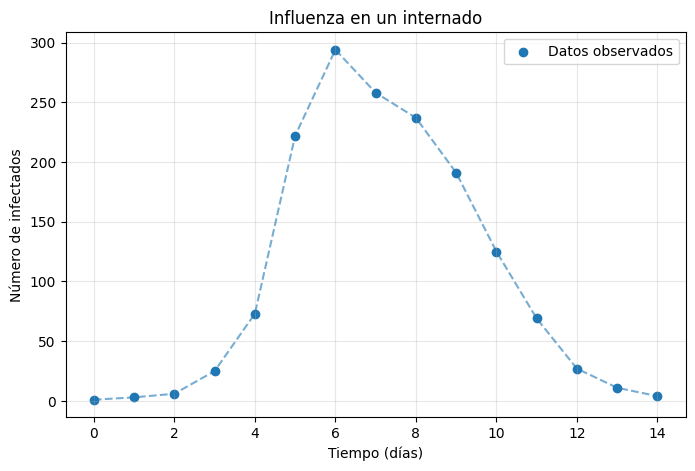

In [3]:
plt.figure(figsize=(8,5))

plt.scatter(t_datos, I_datos, label="Datos observados")
plt.plot(t_datos, I_datos, "--", alpha=0.6)

plt.xlabel("Tiempo (días)")
plt.ylabel("Número de infectados")
plt.title("Influenza en un internado")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

**Modelo SIR**


El modelo **SIR** consiste en tres Ecuacuiones Diferenciales Ordinarias No Lineales, no tiene una solucion analiticamente explicita. Es basicamente un modelo de enfermedades infecciosas.
Consiste en:
$$\frac{dS}{dt}=-aSI$$
$$\frac{dI}{dt}=aSI-bI$$
$$\frac{dR}{dt}=bI$$
donde
* $S=S(t)$ es susceptible
* $I(t)$ es infectado
* $R(t)$ es recuperado
* $a$ es la tasa de transmisión
* $b$ es la tasa de recuperación promedio

En cualquier momento, la población total es  $N = S + I + R$ y permanece constante como $N = S+ I+ R = 0$, donde el punto superior
indica la derivada con respecto al tiempo $t$.

Inicialmente, $S(t)$ es aproximadamente igual a $N$ e $I(t)$ es muy pequeño. En un brote, típicamente $I(t)$ aumenta cada día hasta alcanzar un máximo y luego tiende a disminuir lentamente.
Resulta particularmente útil determinar el número reproductivo, definido como $R_0 = \frac{a}{b}$ ya que el análisis del sistema dinámico indica que:
$$\frac{I_{max}}{N}=1-\frac{1}{R_0}(1+logR_0)$$

Por tanto, determinar los parámetros del modelo permite establecer el número máximo de infectados, una cifra que puede resultar útil para desarrollar medidas de salud pública. Incluso una vez ocurrido el evento, conocer los parámetros *a* y *b* del modelo es de interés, ya que sirven para caracterizar la enfermedad. Este es precisamente el problema que nos interesa resolver: determinar el par de parámetros $(a, b)$ del modelo $SIR$ a partir de un conjunto de datos.

2. Programar la solucion numerica del modelo SIR.

In [4]:
def modelo_SIR(t, y, a, b):
    S, I, R = y

    dSdt = -a*S*I         #Ecuacion de susceptibles
    dIdt =  a*S*I - b*I   #Ecuacion de infectados
    dRdt =  b*I           #Ecuacion de recuperados

    return [dSdt, dIdt, dRdt]

In [5]:
# Condiciones iniciales
N = 763     #Población total

S0 = 762    #Susceptibles inicialmente
I0 = 1      #Infectados inicialmente
R0 = 0      #Recuperados inicialmente

y0 = [S0, I0, R0]

# Instantes donde tenemos datos
t_datos = np.arange(0, 15)

def resolver_SIR(a, b):

  solucion = solve_ivp(       #Resolvemos numericamente el sistema.
        fun=lambda t, y: modelo_SIR(t, y, a, b),
        t_span=(0, 14),
        y0=y0,
        t_eval=t_datos,
        method='RK45'
    )

  S = solucion.y[0]
  I = solucion.y[1]
  R = solucion.y[2]

  return S, I, R

In [6]:
a = 0.002
b = 0.4

S, I, R = resolver_SIR(a, b)

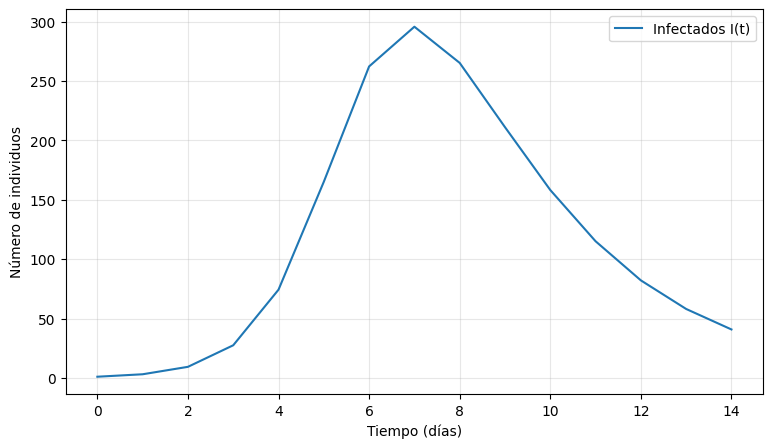

In [7]:
plt.figure(figsize=(9,5))

plt.plot(t_datos, I, label="Infectados I(t)")


plt.xlabel("Tiempo (días)")
plt.ylabel("Número de individuos")


plt.grid(alpha=0.3)
plt.legend()
plt.show()

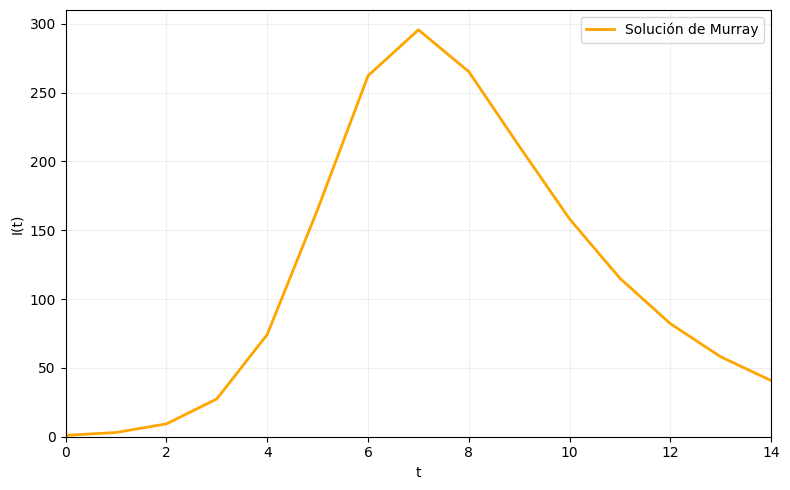

In [8]:
plt.figure(figsize=(8, 5))



# Curva de Murray
plt.plot(
    t_datos,
    I,
    color='orange',
    linewidth=2,
    label="Solución de Murray"
)

plt.xlabel('t')
plt.ylabel('I(t)')

plt.xlim(0, 14)
plt.ylim(0, 310)

plt.legend()
plt.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

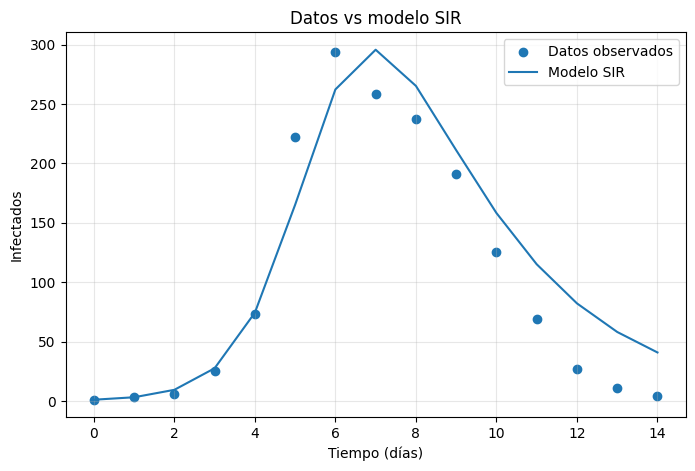

In [9]:
plt.figure(figsize=(8,5))

plt.scatter(
    t_datos,
    I_datos,
    label="Datos observados"
)

plt.plot(
    t_datos,
    I,
    label="Modelo SIR"
)

plt.xlabel("Tiempo (días)")
plt.ylabel("Infectados")
plt.title("Datos vs modelo SIR")

plt.grid(alpha=0.3)
plt.legend()

plt.show()

## 3. Plantear el ajuste por mínimos cuadrados: $\chi^2(a,b)$

A partir de la solución numérica definida arriba, se calcula el error cuadrático entre los infectados observados y los estimados por el modelo.

## Definir la función de error $\chi^2(a,b)$

Para cada par $(a,b)$, resolvemos el modelo SIR y comparamos los infectados predichos con los datos observados.

Usaremos
$$\chi^2(a,b)
=
\sum_i
\left[
I_{\text{modelo}}(t_i;a,b)-I_i^{\text{obs}}
\right]^2.
$$

El mejor ajuste corresponderá a valores de $a$ y $b$ que hagan pequeño este error.

In [10]:
def chi_cuadrada(a, b):

    S, I_modelo, R = resolver_SIR(a, b)

    chi2 = np.sum((I_modelo - I_datos)**2)

    return chi2

# Punto 4. MCMC con Metropolis-Hastings

La idea es recorrer el espacio de parámetros $(a,b)$ mediante una cadena de Markov.

Para utilizar Metropolis-Hastings definimos una función objetivo proporcional a

$$
\pi(a,b)\propto
\exp\left(-\frac{\chi^2(a,b)}{2T}\right).
$$

De esta manera, los valores con menor $\chi^2$ tienen mayor probabilidad de ser aceptados.

Si el candidato es mejor que el estado actual, se acepta automáticamente. Si es peor, todavía puede aceptarse con cierta probabilidad.

## Implementar Metropolis-Hastings

En este bloque se construye el algoritmo.

En cada iteración:

1. Se propone un nuevo valor de $a$ y de $b$ usando distribuciones normales centradas en los valores actuales.
2. Se calcula el nuevo $\chi^2$.
3. Se calcula la probabilidad de aceptación.
4. Se decide aleatoriamente si se acepta o rechaza el nuevo punto.
5. Se guarda el estado de la cadena.

El parámetro `T` controla qué tan fácil es aceptar propuestas peores y, por tanto, ayuda a que la cadena explore el espacio.

In [11]:
def metropolis_hastings(
    n_iter=25000,
    a0=0.002,
    b0=0.40,
    sigma_a=6e-5,
    sigma_b=0.025,
    T=400,
    seed=456
):

    rng = np.random.default_rng(seed)

    cadena = np.zeros((n_iter, 2))
    valores_chi2 = np.zeros(n_iter)

    a_actual = a0
    b_actual = b0

    chi2_actual = chi_cuadrada(a_actual, b_actual)

    aceptados = 0

    for i in range(n_iter):

        # Proponer un nuevo punto
        a_propuesto = rng.normal(a_actual, sigma_a)
        b_propuesto = rng.normal(b_actual, sigma_b)

        # Restringir los parámetros a valores físicamente razonables
        if (a_propuesto <= 0 or a_propuesto >= 0.01 or
            b_propuesto <= 0 or b_propuesto >= 1):

            cadena[i] = [a_actual, b_actual]
            valores_chi2[i] = chi2_actual
            continue

        # Evaluar el error del candidato
        chi2_propuesto = chi_cuadrada(a_propuesto, b_propuesto)

        # Probabilidad de aceptación en escala logarítmica
        log_alpha = -(chi2_propuesto - chi2_actual)/(2*T)

        # Regla de aceptación
        if np.log(rng.random()) < min(0, log_alpha):

            a_actual = a_propuesto
            b_actual = b_propuesto
            chi2_actual = chi2_propuesto

            aceptados += 1

        cadena[i] = [a_actual, b_actual]
        valores_chi2[i] = chi2_actual

    tasa_aceptacion = aceptados/n_iter

    return cadena, valores_chi2, tasa_aceptacion

In [12]:
cadena, chi2_cadena, tasa = metropolis_hastings()

print("Tasa de aceptación:", tasa)

Tasa de aceptación: 0.35824


## Encontrar el mejor par de parámetros

Una vez construida la cadena, buscamos el punto con el menor valor de $\chi^2$.

Ese punto representa el mejor ajuste encontrado por el algoritmo.

In [13]:
indice_mejor = np.argmin(chi2_cadena)

a_mejor = cadena[indice_mejor, 0]
b_mejor = cadena[indice_mejor, 1]
chi2_min = chi2_cadena[indice_mejor]

print("a =", a_mejor)
print("b =", b_mejor)
print("chi² mínimo =", chi2_min)

a = 0.0021798582456276517
b = 0.4456259577781815
chi² mínimo = 4446.787983389339


## Graficar la cadena del parámetro $a$

Esta gráfica permite observar cómo evoluciona el parámetro $a$ a lo largo de las iteraciones.

Si la cadena explora de manera estable una región y deja de mostrar tendencias sistemáticas, es una señal favorable de convergencia.

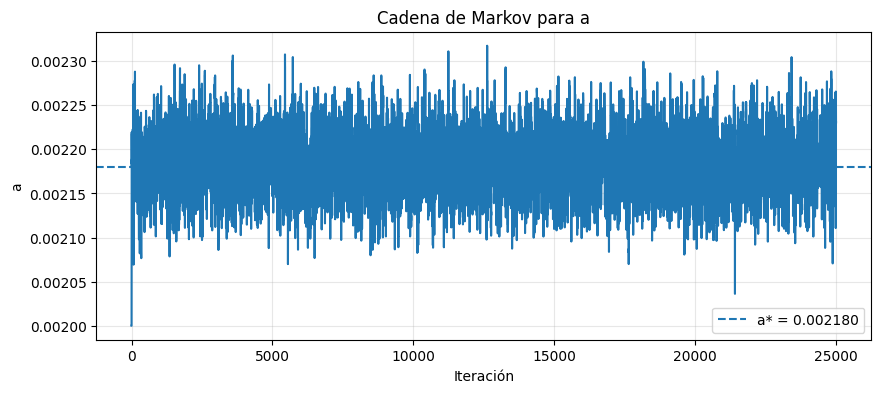

In [14]:
plt.figure(figsize=(10, 4))

plt.plot(cadena[:, 0])

plt.axhline(
    a_mejor,
    linestyle="--",
    label=f"a* = {a_mejor:.6f}"
)

plt.xlabel("Iteración")
plt.ylabel("a")
plt.title("Cadena de Markov para a")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Graficar la cadena del parámetro $b$

Se realiza el mismo análisis para el parámetro $b$.

Esto ayuda a verificar visualmente que el algoritmo no permanece atrapado en un único punto.

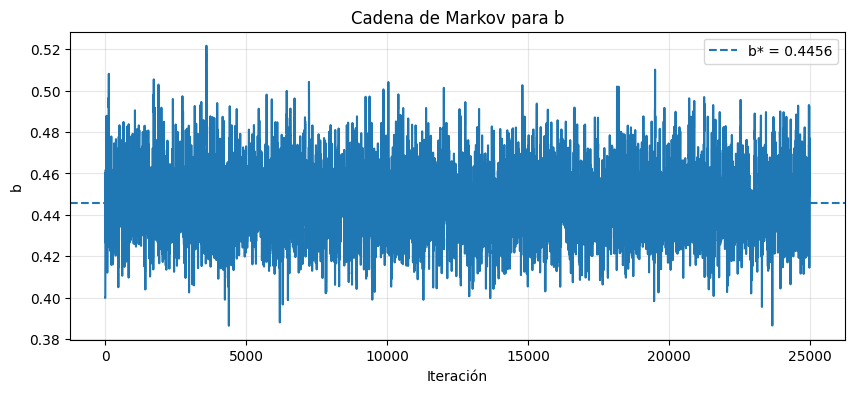

In [15]:
plt.figure(figsize=(10, 4))

plt.plot(cadena[:, 1])

plt.axhline(
    b_mejor,
    linestyle="--",
    label=f"b* = {b_mejor:.4f}"
)

plt.xlabel("Iteración")
plt.ylabel("b")
plt.title("Cadena de Markov para b")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Visualizar el espacio de parámetros

Aquí graficamos simultáneamente los valores de $a$ y $b$ visitados por la cadena.

Se descartan las primeras 5000 iteraciones como **burn-in**, ya que corresponden a la etapa inicial de adaptación de la cadena.

La nube de puntos muestra qué región del espacio de parámetros es explorada con mayor frecuencia.

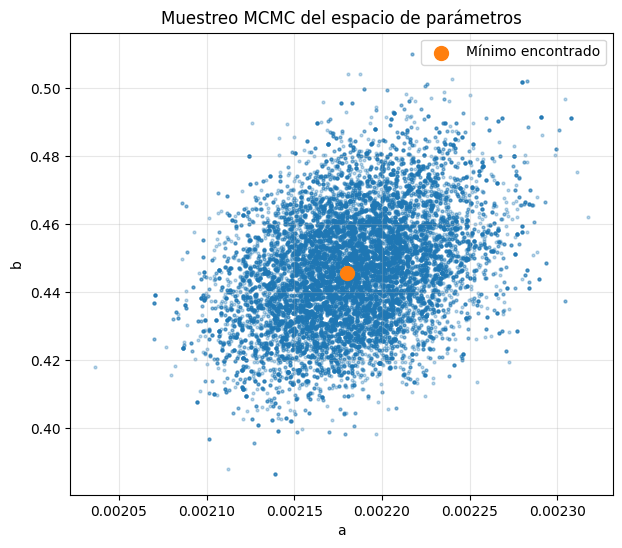

In [16]:
burn = 5000

plt.figure(figsize=(7, 6))

plt.scatter(
    cadena[burn:, 0],
    cadena[burn:, 1],
    s=4,
    alpha=0.3
)

plt.scatter(
    a_mejor,
    b_mejor,
    s=100,
    label="Mínimo encontrado"
)

plt.xlabel("a")
plt.ylabel("b")
plt.title("Muestreo MCMC del espacio de parámetros")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Comparar el mejor modelo SIR con los datos

Usamos los mejores parámetros encontrados para resolver nuevamente el modelo.

Después se compara la curva de infectados predicha con los datos observados.

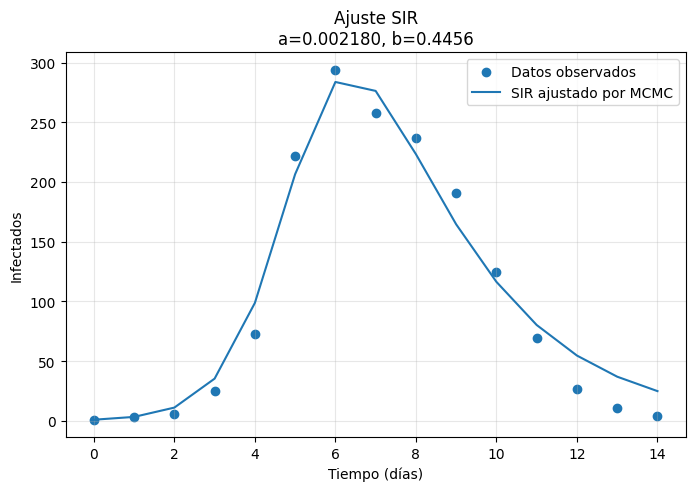

In [17]:
S_mejor, I_mejor, R_mejor = resolver_SIR(
    a_mejor,
    b_mejor
)

plt.figure(figsize=(8, 5))

plt.scatter(
    t_datos,
    I_datos,
    label="Datos observados"
)

plt.plot(
    t_datos,
    I_mejor,
    label="SIR ajustado por MCMC"
)

plt.xlabel("Tiempo (días)")
plt.ylabel("Infectados")

plt.title(
    f"Ajuste SIR\n"
    f"a={a_mejor:.6f}, b={b_mejor:.4f}"
)

plt.grid(alpha=0.3)
plt.legend()
plt.show()